In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")
else:
    print("⚠️ No GPU detected — go to Runtime > Change runtime type > T4 GPU")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 15.64 GB


In [ ]:
!pip install open3d wandb tqdm huggingface_hub -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 125.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 100.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 84.6 MB/s eta 0:00:00


In [ ]:
import os
import glob
import zipfile
import random
import numpy as np
import open3d as o3d
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import wandb
from huggingface_hub import hf_hub_download
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

In [ ]:
os.makedirs("data", exist_ok=True)

data_dir = "data/MaizeField"
print("Downloading raw point clouds...")

zip_path = hf_hub_download(
    repo_id="BGLab/MaizeField3D",
    filename="datasets/FielGrwon_ZeaMays_RawPCD_10k.zip",
    repo_type="dataset",
    local_dir="data"
)

print("Extracting...")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(data_dir)

all_files = sorted(glob.glob(f"{data_dir}/**/*.ply", recursive=True))
print(f"Found {len(all_files)} total plant files.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


datasets/FielGrwon_ZeaMays_RawPCD_10k.zi(…):   0%|          | 0.00/218M [00:00<?, ?B/s]

Extracting...
Found 1045 total plant files.


In [ ]:
import os
import shutil
from google.colab import files

# ── Upload selected_plants.txt ──
uploaded = files.upload()  # select selected_plants.txt

# ── Read the 150 selected paths ──
with open("selected_plants.txt") as f:
    all_ply_files = [line.strip() for line in f.readlines()]

train_files = all_ply_files[:120]
test_files  = all_ply_files[120:]

# ── Create folders ──
os.makedirs("data/train", exist_ok=True)
os.makedirs("data/test",  exist_ok=True)

# ── Copy files ──
for path in train_files:
    shutil.copy(path, "data/train/")

for path in test_files:
    shutil.copy(path, "data/test/")

print(f"Train: {len(os.listdir('data/train'))} files")
print(f"Test:  {len(os.listdir('data/test'))}  files")

Saving selected_plants.txt to selected_plants (1).txt
Train: 120 files
Test:  30  files


In [ ]:
train_files = sorted(glob.glob("data/train/*.ply"))
test_files  = sorted(glob.glob("data/test/*.ply"))

print(f"Train: {len(train_files)}  Test: {len(test_files)}")

Train: 120  Test: 30


In [ ]:
wandb.login()

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


False

In [ ]:
CFG = {
    "data_dir":             "data/MaizeField",
    "num_points":           1024,
    "batch_size":           8,
    "epochs":               150,
    "lr":                   1e-4,
    "latent_dim":           256,
    "vox_res":              32,
    "base_ch":              32,
    "subset_size":          150,
    "train_size":           120,
    "test_size":            30,
    "checkpoint_interval":  25,
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


In [ ]:
def normalize_pc(pc):
    pc = pc - pc.mean(axis=0)
    scale = np.sqrt((pc**2).sum(axis=1)).max()
    pc = pc / (scale + 1e-8)
    return pc

def sample_points(pc, n):
    if pc.shape[0] >= n:
        idx = np.random.choice(pc.shape[0], n, replace=False)
    else:
        idx = np.random.choice(pc.shape[0], n, replace=True)
    return pc[idx]

def voxelize(pts, vox_res):
    R   = vox_res
    idx = ((pts + 1) / 2 * (R - 1)).clip(0, R-1).astype(np.int32)
    grid = np.zeros((R, R, R), dtype=np.float32)
    grid[idx[:,0], idx[:,1], idx[:,2]] = 1.0
    return torch.from_numpy(grid).unsqueeze(0)

In [ ]:
class MaizeDataset(Dataset):
    def __init__(self, files):
        self.files = files

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        pcd    = o3d.io.read_point_cloud(self.files[idx])
        points = np.asarray(pcd.points)

        # ── Clean NaN/Inf ──
        mask   = np.isfinite(points).all(axis=1)
        points = points[mask]

        points = normalize_pc(points)
        points = sample_points(points, CFG["num_points"])

        vox   = voxelize(points, CFG["vox_res"])
        pts_t = torch.tensor(points, dtype=torch.float32)
        return vox, pts_t

train_dataset = MaizeDataset(train_files)
test_dataset  = MaizeDataset(test_files)

train_loader  = DataLoader(train_dataset, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2)
test_loader   = DataLoader(test_dataset,  batch_size=CFG["batch_size"], shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}  Test batches: {len(test_loader)}")

Train batches: 15  Test batches: 4


In [ ]:
class VoxelEncoder(nn.Module):
    def __init__(self, base_ch=32, latent_dim=256):
        super().__init__()
        c = base_ch
        self.net = nn.Sequential(
            nn.Conv3d(1, c,    4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c),    nn.LeakyReLU(0.2),
            nn.Conv3d(c, c*2,  4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c*2),  nn.LeakyReLU(0.2),
            nn.Conv3d(c*2, c*4,4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c*4),  nn.LeakyReLU(0.2),
            nn.Conv3d(c*4, c*8,4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c*8),  nn.LeakyReLU(0.2),
            nn.Conv3d(c*8, c*16, 2, stride=1, padding=0, bias=False), nn.BatchNorm3d(c*16), nn.LeakyReLU(0.2),
        )
        self.fc = nn.Linear(c*16, latent_dim)

    def forward(self, x):
        feat = self.net(x).flatten(1)
        return self.fc(feat)

class VoxelDecoder(nn.Module):
    def __init__(self, base_ch=32, latent_dim=256):
        super().__init__()
        c = base_ch
        self.fc = nn.Linear(latent_dim, c*16)
        self.net = nn.Sequential(
            nn.ConvTranspose3d(c*16, c*8, 2, stride=1, padding=0, bias=False), nn.BatchNorm3d(c*8), nn.ReLU(),
            nn.ConvTranspose3d(c*8, c*4,  4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c*4), nn.ReLU(),
            nn.ConvTranspose3d(c*4, c*2,  4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c*2), nn.ReLU(),
            nn.ConvTranspose3d(c*2, c,    4, stride=2, padding=1, bias=False), nn.BatchNorm3d(c),   nn.ReLU(),
            nn.ConvTranspose3d(c,   1,    4, stride=2, padding=1, bias=False),
        )

    def forward(self, z):
        x = self.fc(z).view(z.size(0), -1, 1, 1, 1)
        return self.net(x)

class VoxelAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = VoxelEncoder(CFG["base_ch"], CFG["latent_dim"])
        self.decoder = VoxelDecoder(CFG["base_ch"], CFG["latent_dim"])

    def forward(self, vox):
        z      = self.encoder(vox)
        logits = self.decoder(z)
        return logits, z

    def vox_to_points(self, logits, num_points=1024):
        B, _, R, _, _ = logits.shape
        device = logits.device                          # ← get device
        probs = torch.sigmoid(logits).squeeze(1)
        pts_batch = []
        for b in range(B):
            occ = (probs[b] > 0.5).nonzero(as_tuple=False).float()
            if occ.shape[0] == 0:
                occ = torch.zeros(1, 3).to(device)     # ← send to device
            occ = occ / (R - 1) * 2 - 1
            idx = torch.randint(0, occ.shape[0], (num_points,))
            pts_batch.append(occ[idx])
        return torch.stack(pts_batch).to(device)        # ← send to device

bce_loss = nn.BCEWithLogitsLoss()

def chamfer_loss(pred, gt):
    diff = pred.unsqueeze(2) - gt.unsqueeze(1)
    dist = (diff**2).sum(-1)
    return dist.min(dim=2).values.mean() + dist.min(dim=1).values.mean()

print(" Model defined")

 Model defined


In [ ]:
wandb.init(
    project = "maize-pointcloud",
    name    = "voxel-150plants-150epochs-2",
    config  = CFG
)

model     = VoxelAutoencoder().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

train_losses = []
test_losses  = []

import time
train_start = time.time()

for epoch in range(CFG["epochs"]):

    # ── Train ──
    model.train()
    total_loss = 0
    for vox, pts in tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['epochs']}"):
        vox, pts  = vox.to(DEVICE), pts.to(DEVICE)
        logits, _ = model(vox)
        loss_bce  = bce_loss(logits, vox)
        recon_pts = model.vox_to_points(logits, CFG["num_points"])
        loss_cd   = chamfer_loss(recon_pts, pts) * 0.1
        loss      = loss_bce + loss_cd
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_train_loss = total_loss / len(train_loader)

    # ── Test ──
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for vox, pts in test_loader:
            vox, pts  = vox.to(DEVICE), pts.to(DEVICE)
            logits, _ = model(vox)
            test_loss += bce_loss(logits, vox).item()
    avg_test_loss = test_loss / len(test_loader)

    train_losses.append(avg_train_loss)
    test_losses.append(avg_test_loss)

    log_train = np.log(avg_train_loss) if avg_train_loss > 0 else float('-inf')
    log_test  = np.log(avg_test_loss)  if avg_test_loss  > 0 else float('-inf')

    print(f"Epoch {epoch+1:3d} | Train {avg_train_loss:.6f} (log {log_train:.4f}) | Test {avg_test_loss:.6f} (log {log_test:.4f})")

    wandb.log({
        "epoch":          epoch + 1,
        "train_loss":     avg_train_loss,
        "test_loss":      avg_test_loss,
        "log_train_loss": log_train,
        "log_test_loss":  log_test,
    })

    if (epoch + 1) % CFG["checkpoint_interval"] == 0:
        torch.save(model.state_dict(), f"voxel_checkpoint_epoch_{epoch+1}.pth")
        print(f"   Checkpoint saved at epoch {epoch+1}")

train_time = time.time() - train_start
print(f"\n Training complete — {train_time/60:.2f} minutes")
wandb.log({"training_time_minutes": train_time/60})
wandb.finish()

Epoch 1/150: 100%|██████████| 15/15 [00:00<00:00, 24.32it/s]


Epoch   1 | Train 0.642441 (log -0.4425) | Test 0.665426 (log -0.4073)


Epoch 2/150: 100%|██████████| 15/15 [00:00<00:00, 27.05it/s]


Epoch   2 | Train 0.527227 (log -0.6401) | Test 0.532982 (log -0.6293)


Epoch 3/150: 100%|██████████| 15/15 [00:00<00:00, 21.86it/s]


...

Epoch 149/150: 100%|██████████| 15/15 [00:00<00:00, 25.78it/s]


Epoch 149 | Train 0.012687 (log -4.3672) | Test 0.023799 (log -3.7381)


Epoch 150/150: 100%|██████████| 15/15 [00:00<00:00, 26.14it/s]


Epoch 150 | Train 0.012522 (log -4.3803) | Test 0.023815 (log -3.7374)
   Checkpoint saved at epoch 150

 Training complete — 2.20 minutes


epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇██
log_test_loss,█▇▇▆▅▅▄▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
log_train_loss,██▇▇▇▆▅▅▅▄▄▄▃▄▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁
test_loss,█▅▄▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss,█▆▅▄▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
training_time_minutes,▁
epoch,150
log_test_loss,-3.73742
log_train_loss,-4.38031
test_loss,0.02382
train_loss,0.01252


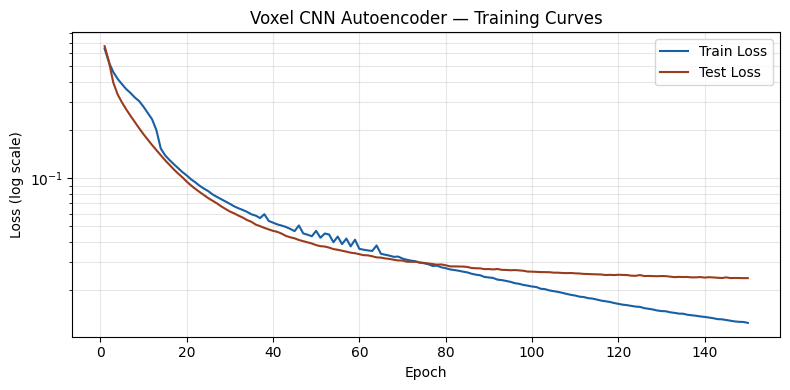

In [ ]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 4))
plt.semilogy(epochs, train_losses, label='Train Loss', color='#185FA5')
plt.semilogy(epochs, test_losses,  label='Test Loss',  color='#993C1D')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.title('Voxel CNN Autoencoder — Training Curves')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig("voxel_loss_curve.png", dpi=150)
plt.show()

In [ ]:
def visualize_reconstruction_plotly(model, dataset, device, num_samples=3):
    model.eval()
    for i in range(num_samples):
        idx      = np.random.randint(len(dataset))
        vox, pts = dataset[idx]
        vox      = vox.unsqueeze(0).to(device)
        pts_np   = pts.numpy()

        with torch.no_grad():
            logits, _ = model(vox)
            recon_pts = model.vox_to_points(logits, CFG["num_points"])

        recon_np = recon_pts.squeeze(0).cpu().numpy()

        fig = make_subplots(
            rows=1, cols=2,
            specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]],
            subplot_titles=(f"Original (Sample {i+1})", f"Reconstruction (Sample {i+1})")
        )
        fig.add_trace(go.Scatter3d(
            x=pts_np[:,0], y=pts_np[:,1], z=pts_np[:,2], mode="markers",
            marker=dict(size=2, color=pts_np[:,2], colorscale="Viridis", opacity=0.8),
            name="Original"), row=1, col=1)
        fig.add_trace(go.Scatter3d(
            x=recon_np[:,0], y=recon_np[:,1], z=recon_np[:,2], mode="markers",
            marker=dict(size=2, color=recon_np[:,2], colorscale="Plasma", opacity=0.8),
            name="Reconstruction"), row=1, col=2)
        fig.update_layout(title=f"Voxel CNN — Sample {i+1}", height=500)
        fig.show()

visualize_reconstruction_plotly(model, test_dataset, DEVICE, num_samples=3)

In [ ]:
from scipy.spatial import KDTree

def fscore(pred, gt, tau=None):
    if tau is None:
        diag = np.linalg.norm(gt.max(axis=0) - gt.min(axis=0))
        tau  = 0.01 * diag
    tree_gt   = KDTree(gt)
    tree_pred = KDTree(pred)
    d_pred, _ = tree_gt.query(pred)
    precision  = (d_pred < tau).mean()
    d_gt, _   = tree_pred.query(gt)
    recall     = (d_gt < tau).mean()
    if precision + recall < 1e-8:
        return 0.0, 0.0, 0.0
    f = 2 * precision * recall / (precision + recall)
    return float(precision), float(recall), float(f)

def chamfer_numpy(pred, gt):
    d1 = KDTree(gt).query(pred)[0].mean()
    d2 = KDTree(pred).query(gt)[0].mean()
    return d1 + d2

model.eval()
cd_scores, f_scores, prec_scores, rec_scores, latents = [], [], [], [], []

with torch.no_grad():
    for vox, pts in test_loader:
        vox, pts  = vox.to(DEVICE), pts.to(DEVICE)
        logits, z = model(vox)
        recon_pts = model.vox_to_points(logits, CFG["num_points"])

        for i in range(pts.shape[0]):
            gt_np   = pts[i].cpu().numpy()
            pred_np = recon_pts[i].cpu().numpy()

            cd      = chamfer_numpy(pred_np, gt_np)
            p, r, f = fscore(pred_np, gt_np)

            cd_scores.append(cd)
            f_scores.append(f)
            prec_scores.append(p)
            rec_scores.append(r)
            latents.append(z[i].cpu().numpy())

cd_scores = np.array(cd_scores)
f_scores  = np.array(f_scores)
latents   = np.array(latents)

print("="*50)
print(f"CD mean:       {cd_scores.mean():.6f}")
print(f"CD std:        {cd_scores.std():.6f}")
print(f"F-Score mean:  {f_scores.mean():.4f}")
print(f"Precision:     {np.array(prec_scores).mean():.4f}")
print(f"Recall:        {np.array(rec_scores).mean():.4f}")
print("="*50)

np.save("voxel_cd_scores.npy", cd_scores)
np.save("voxel_f_scores.npy",  f_scores)
np.save("voxel_latents.npy",   latents)
print("✅ Saved voxel_cd_scores, voxel_f_scores, voxel_latents")

CD mean:       0.185528
CD std:        0.038816
F-Score mean:  0.0485
Precision:     0.2040
Recall:        0.0278
✅ Saved voxel_cd_scores, voxel_f_scores, voxel_latents
